In [9]:
import pandas as pd
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import datetime
import pytz

In [10]:
# Generalized heatmap plotting function
def plot_heatmap(df, color_map, value_column, title, rows, cols):
    """
    Plots a heatmap for a specified column and its corresponding color map.

    Parameters:
    - df: The DataFrame containing the data.
    - color_map: A dictionary mapping values in the value_column to colors.
    - value_column: The column name in df to display values in each cell.
    - title: The title of the heatmap.
    - rows: Number of rows in the plate.
    - cols: Number of columns in the plate.
    """
    fig, ax = plt.subplots(figsize=(16, 8))  # Adjust the size as needed
    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.invert_yaxis()  # Invert Y-axis for top-down orientation
    
    for _, row in df.iterrows():
        well_position = row["Well Position"]
        value = row[value_column]
        color_str = color_map.get(value, "RGB(255,255,255)")  # Default to white if no color is assigned
        color = convert_rgb_string_to_tuple(color_str)
        
        # Get row and column indices from the well position
        row_idx = ord(well_position[0]) - 65  # Convert letter to index (A=0, B=1, ...)
        col_idx = int(well_position[1:]) - 1  # Convert number to index (1-based to 0-based)

        # Draw the rectangle with color
        rect = mpatches.Rectangle((col_idx, row_idx), 1, 1, facecolor=color, edgecolor="black", linewidth=0.5)
        ax.add_patch(rect)
        
        # Add text with the value
        ax.text(
            col_idx + 0.5, row_idx + 0.5, value if pd.notna(value) else "",
            ha="center", va="center", fontsize=8, color="black"
        )

    # Set axis labels and ticks
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticklabels([str(i + 1) for i in range(cols)])
    ax.set_yticklabels([chr(65 + i) for i in range(rows)])
    ax.set_xlabel("Columns")
    ax.set_ylabel("Rows")
    
    plt.title(title)
    plt.show()

In [11]:
# Define the path to the folder and file
folder = "/Users/mariaclaudia/Documents/Lab/Experiments/qPCR/260205-FASN_Tg_induced_ER_stress_KR206"  # Update this to your actual folder path
plate_plan_name = "plate_plans.xlsx"  # Update this to your actual file name
file_path = os.path.join(folder, plate_plan_name)
platen = "plate1" # Update this to your actual sheet name if needed



# Load the 16x24 plate data with error handling
try:
    plate_data = pd.read_excel(file_path, header=None, sheet_name=platen)  # Assuming no header in the input file
except FileNotFoundError:
    print(f"Error: The file at {file_path} was not found.")
    exit()
except Exception as e:
    print(f"Error: An unexpected error occurred while reading the file: {e}")
    exit()

# Generate distinct RGB colors
def generate_distinct_colors(num_colors):
    colors = []
    while len(colors) < num_colors:
        color = f"RGB({random.randint(0, 255)},{random.randint(0, 255)},{random.randint(0, 255)})"
        if color not in colors:
            colors.append(color)
    return colors

def convert_rgb_string_to_tuple(rgb_string):
    rgb_values = tuple(map(int, rgb_string[4:-1].split(',')))
    return tuple(value / 255 for value in rgb_values)

# Initialize variables
rows = 16  # Total number of rows in a 384-well plate
cols = 24  # Total number of columns in a 384-well plate
data = []

# Process the plate data
def process_plate_data(plate_data, rows, cols):
    data = []
    for row_idx in range(rows):
        for col_idx in range(cols):
            well_number = row_idx * cols + col_idx
            well_position = f"{chr(65 + row_idx)}{col_idx + 1}"  # A1, A2, ... P24
            if row_idx < plate_data.shape[0] and col_idx < plate_data.shape[1]:
                content = str(plate_data.iloc[row_idx, col_idx])
                # Split the content into sample_name and target_name
                if "," in content:
                    sample_name, target_name = map(str.strip, content.split(",", 1))
                else:
                    sample_name = content.strip()
                    target_name = None  # Handle missing target name
            else:
                sample_name = None
                target_name = None
            # Append to data list
            data.append([well_number, well_position, sample_name, target_name])
    return data

data = process_plate_data(plate_data, rows, cols)

# Create a DataFrame
df = pd.DataFrame(data, columns=["Well", "Well Position", "Sample Name", "Target Name"])

# Create dictionaries for unique sample and target colors
unique_samples = df["Sample Name"].unique()
sample_colors = generate_distinct_colors(len(unique_samples))
sample_color_map = dict(zip(unique_samples, sample_colors))

unique_targets = df["Target Name"].dropna().unique()
target_colors = generate_distinct_colors(len(unique_targets))
target_color_map = dict(zip(unique_targets, target_colors))

# Add color columns
df["Sample Color"] = df["Sample Name"].map(sample_color_map)
df["Target Color"] = df["Target Name"].map(target_color_map)

# Add additional requested columns
df["Biogroup Name"] = ""  # Empty for now
df["Biogroup Color"] = ""  # Empty for now
df["Task"] = "UNKNOWN"
df["Reporter"] = "SYBR"
df["Quencher"] = ""
df["Quantity"] = ""
df["Comments"] = ""

# Reorder the entire DataFrame by moving both columns and their contents to match the specified order
new_order = [
    'Well', 'Well Position', 'Sample Name', 'Sample Color', 'Biogroup Name', 'Biogroup Color',
    'Target Name', 'Target Color', 'Task', 'Reporter', 'Quencher', 'Quantity', 'Comments'    
]
df = df[new_order].copy()

# Define the special rows
timezone = pytz.timezone('Europe/London')
current_time = datetime.datetime.now(timezone).strftime('%a %b %d %H:%M:%S %Z %Y')
header_rows = [
    ["* Block Type = 384-Well Block", "", "", "", "", "", "", "", "", "", "", "", ""],
    [f"* Date Created = {current_time}", "", "", "", "", "", "", "", "", "", "", "", ""],
    ["* Passive Reference = ROX", "", "", "", "", "", "", "", "", "", "", "", ""],
    ["* Barcode = ", "", "", "", "", "", "", "", "", "", "", "", ""],
    ["", "", "", "", "", "", "", "", "", "", "", "", ""],
    ["[Sample Setup]", "", "", "", "", "", "", "", "", "", "", "", ""],
    ["Well", "Well Position", "Sample Name", "Sample Color", "Biogroup Name", "Biogroup Color", "Target Name", "Target Color", 
      "Task", "Reporter", "Quencher", "Quantity", "Comments"]
]

# Create a DataFrame for the header rows
header_df = pd.DataFrame(header_rows, columns=df.columns)

# Offset the Well numbers to start at 1 after the [Sample Setup] row
df["Well"] = range(1, len(df) + 1)

# Concatenate the header rows with the actual data
final_df = pd.concat([header_df, df], ignore_index=True)

# Save the modified DataFrame to CSV
output_csv_path = os.path.join(folder, "transformed_plate_plan_with_headers_" + platen + ".csv")
final_df.to_csv(output_csv_path, index=False, header=False)  # Disable column headers in the CSV

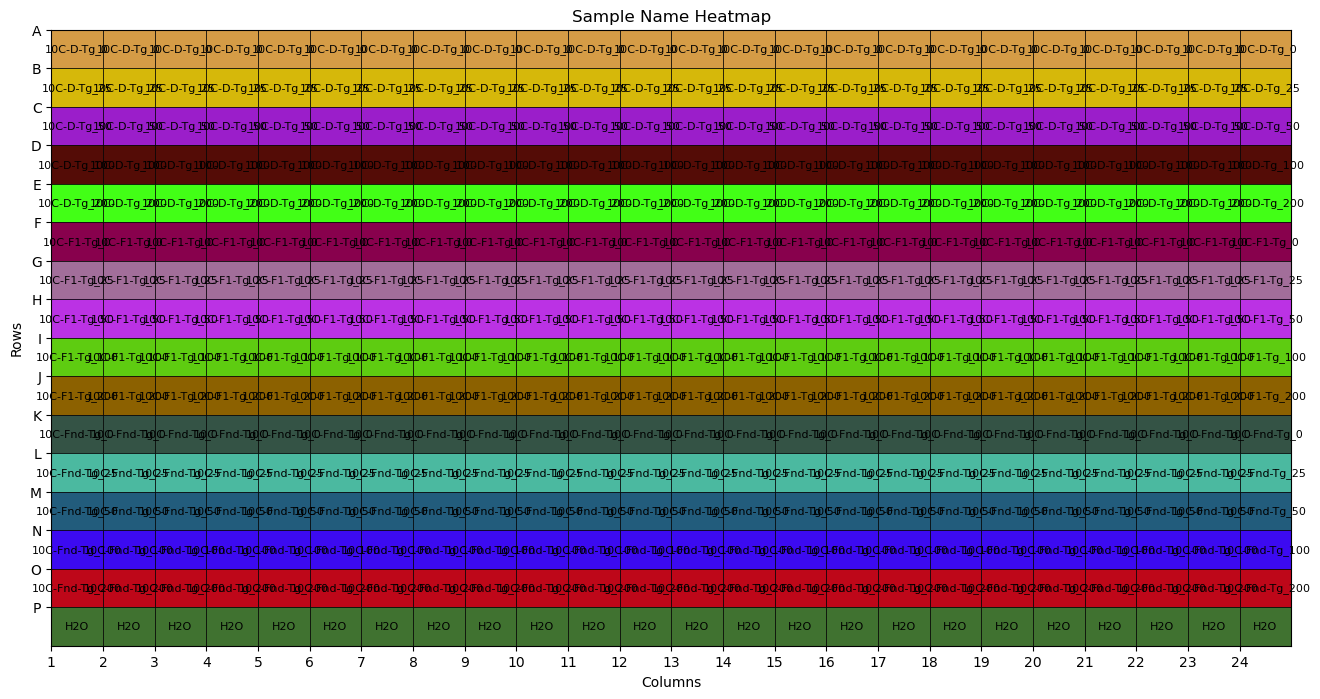

In [12]:
# Plot the heatmap with Samples
plot_heatmap(df, sample_color_map, "Sample Name", "Sample Name Heatmap", rows, cols)

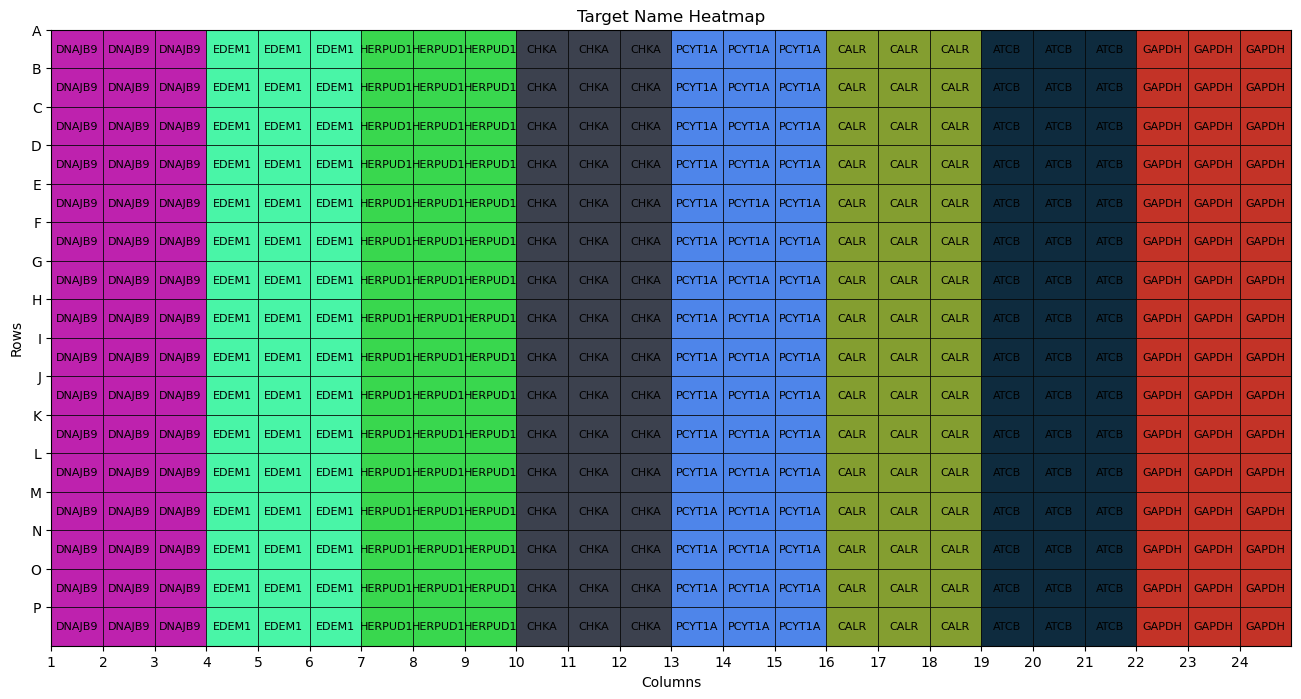

In [13]:
# Plot the heatmap with Targets
plot_heatmap(df, target_color_map, "Target Name", "Target Name Heatmap", rows, cols)